# 04. How complex are the geosciences, and what does that mean for AI readiness?

**Goal.** Measure geoscience complexity along four separate axes, set each against sourced evidence of what AI has and has not achieved, and summarize readiness by discipline as a profile rather than a score.

**Inputs.** All in `docs/complexity_2026-10-30/`, validated by `scripts/complexity_tables.py`:

| File | Content |
|---|---|
| `power_laws.json` | exponents, conventions, tests against alternative distributions |
| `dimensionality.json` | nominal sizes and published effective dimensions |
| `coupled_pdes.json` | balance-equation and state-variable counts per coupled system |
| `unobserved_drivers.json` | sourced gaps in what drives hazard outcomes |
| `ai_evidence.json` | AI successes and limitations along the four axes |
| `readiness_profile.json` | status per discipline and measure, citing row ids |

**Rules.** Every row has a value as stated, units, a DOI or URL, an as-of date, a quote and a flag saying whether the number was read in the source text. Missing values are "not found". The axes are never added together.

Offline: no network call is made here.

In [1]:
import csv, importlib.util, json, subprocess, sys
from collections import Counter
from pathlib import Path
from IPython.display import Image, Markdown, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pixi.toml").exists())
def table(header, rows):
    """Render rows as a Markdown table."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c).replace("|", "/") for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))
def load(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec); spec.loader.exec_module(module)
    return module
ct = load("complexity_tables", ROOT / "scripts/complexity_tables.py")
tables = ct.load()          # raises if any sourcing rule fails
rows = {r["id"]: r for t in tables.values() for r in t["rows"]}
valued = lambda r: any(r[k] is not None for k in ("value", "value_min", "value_max"))
print(ct.summary(tables))

power_laws.json: 34 rows, 31 with a value, 30 of those read in the source text, 0 qualitative, 3 not found
dimensionality.json: 41 rows, 36 with a value, 36 of those read in the source text, 0 qualitative, 5 not found
coupled_pdes.json: 20 rows, 19 with a value, 18 of those read in the source text, 0 qualitative, 1 not found
unobserved_drivers.json: 29 rows, 21 with a value, 20 of those read in the source text, 3 qualitative, 5 not found
ai_evidence.json: 30 rows, 28 with a value, 28 of those read in the source text, 0 qualitative, 2 not found


## 1. Heavy tails: how many observables, and was the power law tested?

Exponents are comparable only within one convention (b-values, survivor-function exponents, density exponents and scaling exponents differ), so the table keeps each convention as stated. The verdict column records whether that source compared the power law with lognormal, stretched-exponential or truncated forms (Clauset, Shalizi & Newman 2009).

In [2]:
pl = tables["power_laws.json"]["rows"]
geo = [r for r in pl if r["domain"] == "geoscience" and valued(r)]
table(["Test status", "Geoscience rows"], sorted(Counter(r["tested_vs_alternatives"] for r in geo).items(), key=lambda x: -x[1]))
table(["id", "Observable", "Symbol", "As stated", "Verdict", "Source", "Read in text"],
      [[r["id"], r["item"], r["symbol"], r["value_text"], r["tested_vs_alternatives"], r["source"], r["checked_in_text"]] for r in pl])

| Test status | Geoscience rows |
|---|---|
| not tested in this source | 7 |
| tested, alternative favored or not distinguishable | 5 |
| tested, power law favored | 4 |
| tested, mixed | 4 |
| not stated | 4 |

| id | Observable | Symbol | As stated | Verdict | Source | Read in text |
|---|---|---|---|---|---|---|
| pl-01 | Earthquake intensities, California 1910-1992 (Clauset data set q) | alpha | 1.64(4) | tested, alternative favored or not distinguishable | Clauset, Shalizi & Newman (2009), SIAM Review | True |
| pl-02 | Seismic moment, southern California catalog | beta | 1.655 (bootstrap 1.65 +/- 0.04) | tested, power law favored | Corral & Gonzalez (2019), Earth and Space Science | True |
| pl-03 | Seismic moment, global CMT catalog | beta | truncated power law beta = 1.655 for 1.3·10^24 to 2·10^27 dyn cm (p 0.46); untruncated beta = 2.087 above 4.0·10^27 dyn cm (p 0.33, n = 97) | tested, mixed | Corral & Gonzalez (2019), Earth and Space Science | True |
| pl-04 | Scalar seismic moment, global shallow CMT catalog 1977-2008 | beta | 0.63–0.67 (catalog estimates); Table 2: 0.6820 global, mt = 5.8, 5450 events; proposed bias-corrected 0.52–0.56 | tested, alternative favored or not distinguishable | Kagan (2010), Tectonophysics | True |
| pl-05 | Gutenberg-Richter b-value, global Harvard CMT shallow earthquakes | b | b1 = 1.00 ± 0.02 (smaller shallow); b2 = 2.3 ± 0.3 (large shallow) | tested, alternative favored or not distinguishable | Sornette, Knopoff, Kagan & Vanneste (1996), Journal of Geophysical Research | True |
| pl-06 | Gutenberg-Richter b-value, southern California catalog | b | b = 1.00 ± 0.02 up to MW ≃ 7.5 | tested, power law favored | Sornette, Knopoff, Kagan & Vanneste (1996), Journal of Geophysical Research | True |
| pl-07 | Gutenberg-Richter b-value, spatiotemporal variability (literature review) | b | 0.3 <= b <= 2.5 (search snippet; long-term average 'close to unity') | not stated | El-Isa & Eaton (2014), Tectonophysics | False |
| pl-08 | Omori-Utsu aftershock decay exponent, worldwide compilation | p | distributed from 0.6 to 2.5 with a median of about 1.1 (abstract: usually p = 0.9-1.5) | tested, mixed | Utsu, Ogata & Matsu'ura (1995), Journal of Physics of the Earth | True |
| pl-09 | Omori-Utsu aftershock decay exponent, southern California (39 sequences) | p | scatter from 0.7 to 1.8 with a mean of 1.11 ± 0.25 | not tested in this source | Utsu, Ogata & Matsu'ura (1995), Journal of Physics of the Earth | True |
| pl-10 | Landslide area, three event inventories (Northridge 1994, Umbria 1997, Hurricane Mitch Guatemala 1998) | rho+1 (stated as exponent -2.40) | -2·40 (i.e. power-law decay with exponent -2.40) | not stated | Malamud, Turcotte, Guzzetti & Reichenbach (2004), Earth Surface Processes and Landforms | True |
| pl-11 | Landslide area, central Italy (Umbria-Marche reconnaissance inventory, 16,809; snowmelt event 1997, 4,233) | alpha (stated as exponent -2.5) | exponent −2.5 for both data sets (0.03-4 km^2 and 0.001-0.1 km^2 ranges) | not stated | Guzzetti, Malamud, Turcotte & Reichenbach (2002), Earth and Planetary Science Letters | True |
| pl-12 | Landslide area, Taiwan and New Zealand inventories | alpha+1 | alpha+1 = 2.11 (Taiwan); alpha+1 = 2.46 ± 0.2 (New Zealand) | tested, mixed | Stark & Hovius (2001), Geophysical Research Letters, as reported in Guzzetti (2006), PhD dissertation ch. 5 'Statistics of landslide size' | True |
| pl-13 | Rockfall volume on subvertical cliffs (Grenoble, Yosemite, worldwide catalogs) | b | 0.5 ± 0.2 (vs 1.2 ± 0.3 for mixed landslide types); Grenoble b ≈ 0.40 ± 0.06 | tested, power law favored | Dussauge, Grasso & Helmstetter (2003), Journal of Geophysical Research | True |
| pl-14 | Flood peak discharge, partial-duration series at six USGS stations (41-95,300 km^2, 74-110 yr) | a | a ranging from 0.27 to 0.90 | not stated | Malamud & Turcotte (2006), Journal of Hydrology | True |
| pl-15 | Fault / fracture length distribution (review) | a | not found | not stated | Bonnet, Bour, Odling, Davy, Main, Cowie & Berkowitz (2001), Reviews of Geophysics | False |
| pl-16 | Hack's law, Virginia and Maryland streams (original) | h (exponent 0.6 in Hack's eq. 3) | L = 1.4 A^0.6 (coefficient averages about 1.4, ranges 1 to 2.5) | not tested in this source | Hack (1957), USGS Professional Paper 294-B | True |
| pl-17 | Hack's exponent, real river networks (compilation) | h | 0.57 < h < 0.60 | not tested in this source | Dodds & Rothman (1999), Physical Review E, citing Maritan et al. (1996), Phys. Rev. E 53, 1510 (doi 10.1103/PhysRevE.53.1510) | True |
| pl-18 | Drainage (contributing) area distribution, real river networks | tau | 1.43 ± 0.02 (text: cited values 1.41 < tau < 1.45) | not tested in this source | Dodds & Rothman (1999), Physical Review E, citing Maritan et al. (1996), Phys. Rev. E 53, 1510 (doi 10.1103/PhysRevE.53.1510) | True |
| pl-19 | Explosive volcanic eruption size, VEI >= 3 (global eruption databases) | k | k = 1.95 (xmin = 10^7 m^3, VEI 3); KS p-value 0.65 | not tested in this source | Papale (2018), Scientific Reports | True |
| pl-20 | Large explosive eruption magnitude-frequency, Holocene global database (M >= 4) | None | not found | not stated | Deligne, Coles & Sparks (2010), Journal of Geophysical Research | False |
| pl-21 | Wildfire burned area, USA and Australia (incl. paleo-fire records) | beta | beta ranging from 1.3 to 1.5 (Malamud et al. 2005, 18 US ecoregions: 1.3 to 1.75) | not tested in this source | Malamud, Morein & Turcotte (1998), Science, as reported in Corral & Gonzalez (2019), Earth and Space Science | True |
| pl-22 | Wildfire burned area, Angola (Landsat, 4 years) | beta | beta = 1.818 above 63 ha (p 0.22, n 1,294, 3.63 decades); bootstrap 1.79 ± 0.07 | tested, alternative favored or not distinguishable | Corral & Gonzalez (2019), Earth and Space Science | True |
| pl-23 | Wildfire burned area, Canada boreal forest (Landsat, 14 years) | beta | truncated power law beta = 1.153 for 1.0-12,600 ha (p 0.23, n 395); bootstrap 1.21 ± 0.08 | tested, mixed | Corral & Gonzalez (2019), Earth and Space Science | True |
| pl-24 | Wildfire size, US federal land 1986-1996 (Clauset data set o) | alpha | 2.2(3) | tested, alternative favored or not distinguishable | Clauset, Shalizi & Newman (2009), SIAM Review | True |
| pl-25 | Solar flare peak gamma-ray intensity 1980-1989 (Clauset data set p; heliophysics, kept per task scope) | alpha | 1.79(2) | tested, alternative favored or not distinguishable | Clauset, Shalizi & Newman (2009), SIAM Review | True |
| pl-26 | Tropical cyclone power dissipation index (PDI), North Atlantic + Northeast Pacific | beta | beta = 1.156 for 0.16-10 x10^10 m^3 s^-2 (p 0.26, n 777); text: 'in the range 1.1–1.2'; bootstrap 1.08 ± 0.26 | tested, power law favored | Corral & Gonzalez (2019), Earth and Space Science | True |
| pl-27 | Tsunami run-up heights, ten locations in Japan (NGDC data) | None | not found | not stated | Burroughs & Tebbens (2005), Pure and Applied Geophysics | False |
| pl-28 | Coastline / frontier fractal dimension (Richardson's divider data) | D | D = 1.25 west coast of Britain; 1.15 German land frontier (c. 1899); 1.14 Spain-Portugal; 1.13 Australian coast; 1.02 South Africa | not tested in this source | Mandelbrot (1967), Science | True |
| pl-29 | Frequency of word use, Moby Dick (Clauset data set a) | alpha | 1.95(2) | tested, power law favored | Clauset, Shalizi & Newman (2009), SIAM Review | True |
| pl-30 | Population of US cities, 2000 Census (Clauset data set m) | alpha | 2.37(8) | tested, alternative favored or not distinguishable | Clauset, Shalizi & Newman (2009), SIAM Review | True |
| pl-31 | Citations to papers published 1981 (Science Citation Index; Clauset data set u) | alpha | 3.16(6) | tested, alternative favored or not distinguishable | Clauset, Shalizi & Newman (2009), SIAM Review | True |
| pl-32 | Hits to web sites, AOL users, one day (Clauset data set w) | alpha | 1.81(8) | tested, alternative favored or not distinguishable | Clauset, Shalizi & Newman (2009), SIAM Review | True |
| pl-33 | Net worth of richest US individuals, Oct 2003 (Clauset data set t) | alpha | 2.3(1) | tested, alternative favored or not distinguishable | Clauset, Shalizi & Newman (2009), SIAM Review | True |
| pl-summary-clauset | Clauset et al. 24 empirical data sets (summary) | None | 17 of the 24 data sets | tested, mixed | Clauset, Shalizi & Newman (2009), SIAM Review | True |

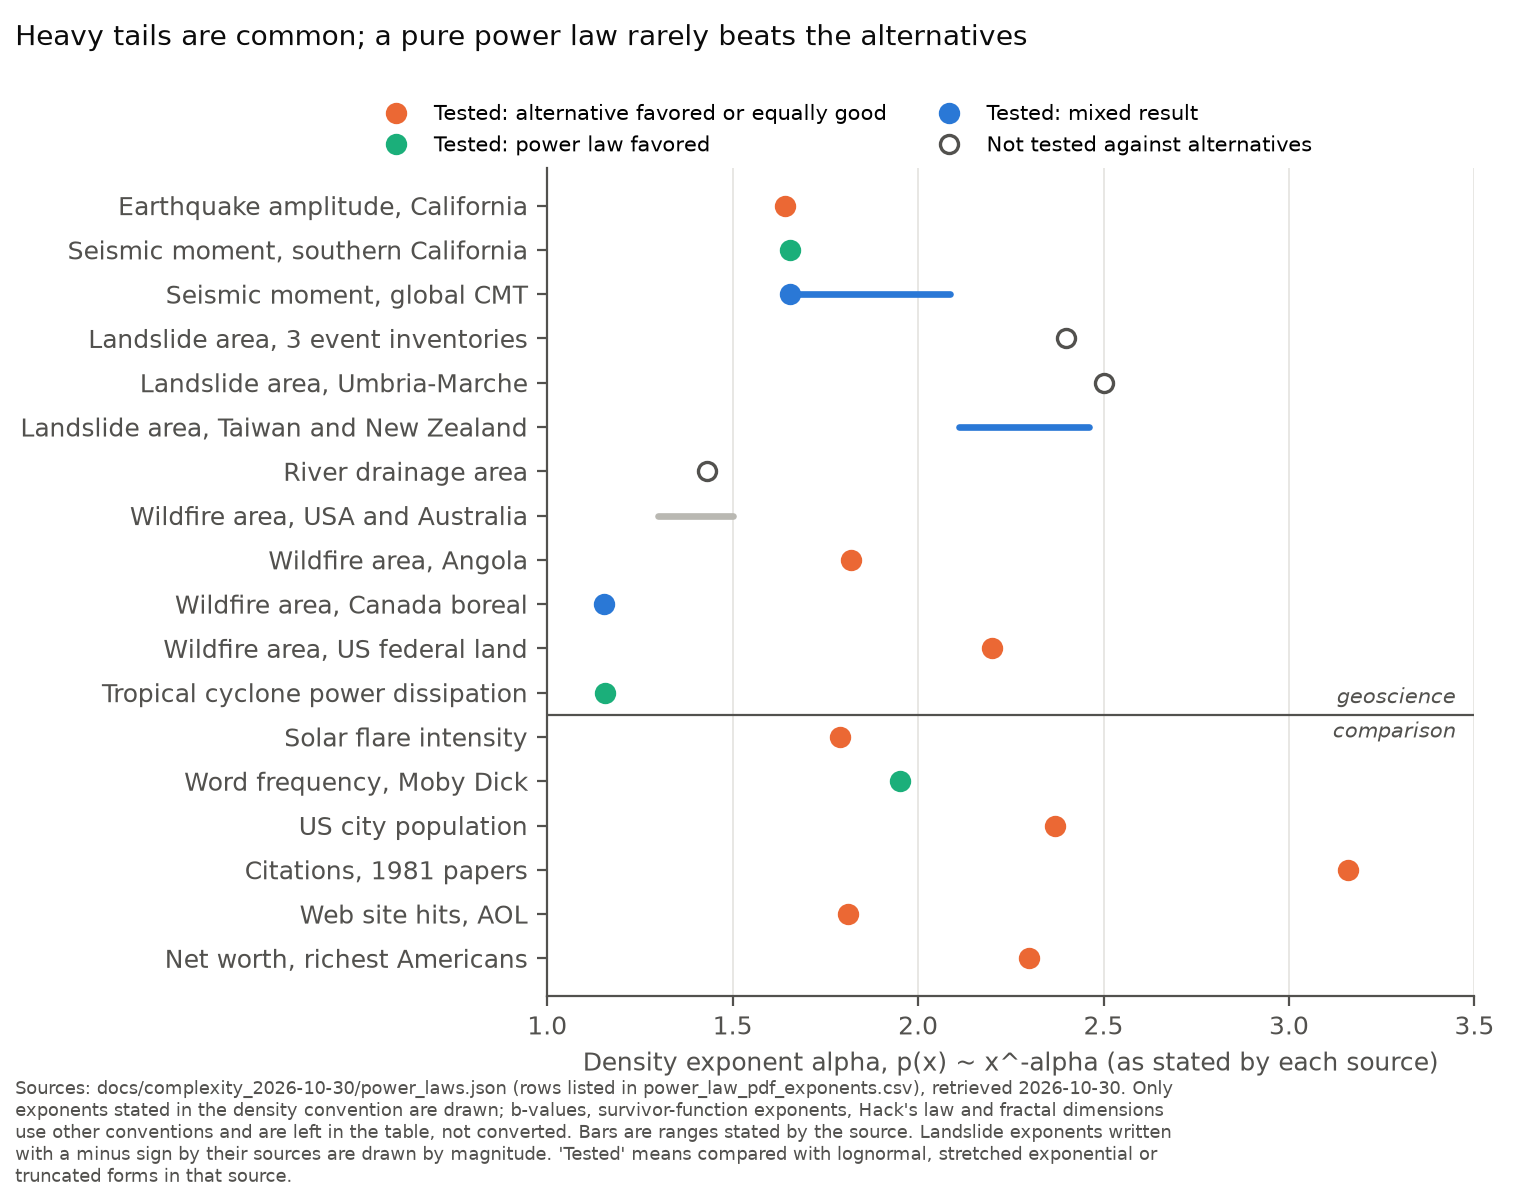

In [3]:
subprocess.run([sys.executable, str(ROOT / "scripts/complexity_figures.py")], check=True, cwd=ROOT, capture_output=True)
FIG = ROOT / "build/complexity"
display(Image(str(FIG / "fig1_power_law_exponents.png"), width=760))

**Reading.** Heavy tails appear for every hazard class in the table, and the density exponents overlap those of the non-geoscience sets in Clauset et al. (2009). Where the form was tested, a pure power law rarely beat the alternatives. The largest events, where losses concentrate, therefore sit on a functional form the data do not settle. This is where models trained on typical events are least trustworthy.

## 2. Dimensionality: nominal size against published effective dimension

Nominal rows give named axes and their stated sizes. Effective rows give a published estimate by a named estimator (EOF count, effective spatial degrees of freedom, attractor dimension, maximum-likelihood intrinsic dimension). The estimate depends on region, variable, period, threshold and estimator.

In [4]:
dims = tables["dimensionality.json"]["rows"]
for kind in ("nominal", "effective"):
    display(Markdown(f"**{kind.capitalize()} rows**"))
    table(["id", "Data set", "Quantity", "As stated", "Source"],
          [[r["id"], r["item"], r["quantity"], r["value_text"], r["source"]] for r in dims if r["kind"] == kind])

**Nominal rows**

| id | Data set | Quantity | As stated | Source |
|---|---|---|---|---|
| dim-01 | ERA5 HRES atmosphere | horizontal grid spacing of the native HRES analysis | 31 km (vs 80 km for ERA-Interim) | Hersbach et al. (2020), Quarterly Journal of the Royal Meteorological Society |
| dim-02 | ERA5 HRES atmosphere | temporal cadence of analyses | hourly output throughout | Hersbach et al. (2020), Quarterly Journal of the Royal Meteorological Society |
| dim-03 | ERA5 HRES atmosphere | number of vertical model levels | 137 hybrid sigma/pressure (model) levels, top at 0.01 hPa | ECMWF (2026), ERA5: data documentation, Copernicus Knowledge Base (Confluence) |
| dim-04 | ERA5 on pressure levels, CDS distribution | horizontal grid of the regridded CDS product | Reanalysis: 0.25° x 0.25°; 37 pressure levels, 1000 hPa to 1 hPa; hourly; 1940 to present | Copernicus Climate Data Store (2026), ERA5 hourly data on pressure levels from 1940 to present, dataset overview |
| dim-06 | CMIP6 total archive | projected total output volume | between 20 and 40 petabytes | Eyring et al. (2016), Geoscientific Model Development |
| dim-07 | CMIP6 Data Request (DREQ v01.00.31) | number of requested variables | 2068 variables, 273 experiments and 93 objectives; more than 2000 distinct CMOR variables | Juckes et al. (2020), Geoscientific Model Development |
| dim-08 | Sacramento dark-fiber DAS array (West Sacramento to Woodland, CA, 27 km) | number of channels | 12000 channels sampled at 500 Hz; 2 m spatial sampling; 10 m gauge length | Ajo-Franklin et al. (2019), Scientific Reports |
| dim-09 | Sacramento dark-fiber DAS array | total raw data volume at demobilization | approximately 0.3 PB of raw data (128 TB in first 3 months) | Ajo-Franklin et al. (2019), Scientific Reports |
| dim-10 | OOI Regional Cabled Array RAPID DAS test (offshore central Oregon, Nov 2021, 4 days) | total data volume | 26 TB total; most data at 200 Hz with gauge lengths 30-50 m; some up to 1000 Hz and gauge lengths down to 3 m; 2 m channel spacing | Wilcock et al. (2023), JASA Express Letters |
| dim-11 | PoroTomo Brady Hot Springs horizontal DAS (Nevada, 2016) | number of channels | around 8000 channels recording at 1000 samples per second; ~8 km fiber, 1 m channel spacing | Issah & Martin (n.d., CWP-1027), Center for Wave Phenomena Report, Colorado School of Mines |
| dim-12 | Lindsey et al. (2017) Stanford/Fairbanks/Northern California DAS arrays | number of channels and sampling rate | not found | Lindsey et al. (2017), Geophysical Research Letters |
| dim-14 | EarthScope/FDSN continuous waveform archive processed on AWS | number of stations with continuous records, 2002-2025 | 47,354 stations spanning 2002-2025 | Ni et al. (2025), Seismica (arXiv 2505.18874) |
| dim-15 | EarthScope/FDSN continuous waveform archive processed on AWS | volume of continuous seismic data processed | 1.3 PB continuous seismic data; 4.3 billion P and S picks | Ni et al. (2025), Seismica (arXiv 2505.18874) |
| dim-16 | FDSN channel band codes | sampling rate of high-broadband (H) channels | H, High Broadband: >= 80 to < 250 samples/s, corner period >= 10 s; B, Broadband: >= 10 to < 80 | FDSN (n.d.), FDSN Source Identifiers specification v1.0, channel codes |
| dim-19 | Sentinel-1 Interferometric Wide swath mode | swath width of one acquisition | 250 km swath at 5 m by 20 m spatial resolution (single look); 12-day repeat per satellite, 6-day with two satellites | ESA (n.d.), SentiWiki, S1 Mission |
| dim-20 | Volcano InSAR time series (general statement) | pixels per interferogram | 10^3 - 10^7 pixels per interferogram; 10^1 - 10^2 interferograms per time series | Gaddes et al. (2018), Journal of Geophysical Research: Solid Earth |
| dim-23 | Nevada Geodetic Laboratory (NGL) global processing | number of GPS stations processed | more than 17,000 stations; daily positions updated weekly for some 10,000 stations; 5-minute positions daily for more than 5,000 | Blewitt et al. (2018), Eos |
| dim-30 | Combined land-ocean monthly temperature anomaly grid (Jones), NH, 1955-94 | number of grid points used | 1002 grid points in the NH (5 x 5 degree grid); 738 in the SH | Wang & Shen (1999), Journal of Climate |
| dim-35 | CyberShake Study 22.12 (Southern California, UCERF2-based) | number of simulated ground-motion records | 335 sites; 9,283 rupture scenarios; more than 770,000 rupture variations; ~626,000 rupture variations per site; 206.7 million ground-motion records after 200 km filter; 0-1 Hz deterministic plus 1-50 Hz stochastic | Zhao, Lavrentiadis & Asimaki (2026), arXiv 2605.24284 |
| dim-36 | Record global seismic wave simulation on Jaguar (ORNL), 2008 | shortest resolved period | shortest period of 1.15 seconds, 161 teraflops, 149,784 cores; grid-point count not found | San Diego Supercomputer Center (2008), press release PR112408 |
| dim-37 | MITgcm LLC4320 global ocean simulation | number of vertical levels (horizontal 1/48 degree, ~2 km at equator) | 1/48-degree (2km at equator) nominal horizontal resolution; 90 vertical levels | NASA JPL PO.DAAC (n.d.), Pre-SWOT LLC4320 README |

**Effective rows**

| id | Data set | Quantity | As stated | Source |
|---|---|---|---|---|
| dim-05 | ERA5 fields | intrinsic or effective dimension of ERA5 fields | not found | none found in searches of 2026-10-30 |
| dim-13 | FORESEE-urban dark-fiber DAS (Pennsylvania) and Brady Hot Springs DAS | low-rank SVD compression behaviour (no rank or variance fraction stated) | SVD compression tested at 5x to 100x; detection significance of mid-sized and large events preserved at 100x; error growth explained by a close to uniform distribution of singular values | Issah & Martin (n.d., CWP-1027), Center for Wave Phenomena Report, Colorado School of Mines |
| dim-17 | Volcanic tremor, Stromboli (1997 broadband network) | embedding dimension of reconstructed phase space of tremor | around five | Taylor et al. (2010), arXiv 1007.3553, citing De Lauro et al. (2008), J. Geophys. Res. 113, B02302 |
| dim-18 | Broadband seismograms, global or regional archive | intrinsic dimension or PCA variance spectrum of seismograms | not found | none found in searches of 2026-10-30 |
| dim-21 | Wolf Volcano (Galapagos) 2015 eruption, 20 daisy-chain descending Sentinel-1 interferograms, 2014-12-13 to 2015-10-21, coherence < 0.8 masked | number of independent components retained / recovered | six components recovered from 20 interferograms; components 1, 2 and 6 interpreted as deformation (three signals), the rest atmospheric; PCs 6-20 judged turbulent atmosphere | Gaddes et al. (2018), Journal of Geophysical Research: Solid Earth |
| dim-22 | Calbuco (Chile) 2015 eruption, ~50 x 50 km subset of Sentinel-1A track 164 daisy-chain interferograms | dimension retained after PCA whitening before ICA | Twelve interferograms ... data dimensions were reduced to ten | Ebmeier (2016), Journal of Geophysical Research: Solid Earth |
| dim-24 | 87 JPL PPP (GIPSY-OASIS) stations in Central Europe, daily residual time series (trend and seasonals removed), 2002.65-2011.83, North component | variance fraction explained by the first principal component of common-mode error | first principal component computed for North explains nearly 40 % of the variation, while the first PC for East and Up accounts for more than half | Gruszczynski et al. (2016), Acta Geodynamica et Geomaterialia |
| dim-25 | Southern California Integrated GPS Network (SCIGN) daily coordinates, 2000-2004 | variance fraction of common-mode error in leading PC | not found | Dong et al. (2006), Journal of Geophysical Research: Solid Earth |
| dim-26 | Northern Hemisphere wintertime 500-mb height pentads, DJF 1946-93 (48 winters), NMC analyses, 5 x 7.5 degree grid north of 20N, 672 grid points, anomalies, area-weighted | effective number of spatial degrees of freedom, eigenvalue formula | N*ef ≈ 19 (fitted 18.5); first N*ef EOFs explain about 82% of the variance | Bretherton et al. (1999), Journal of Climate |
| dim-27 | Same NH DJF 500-mb pentad data set as dim-26 (672 grid points, 1946-93) | effective number of spatial degrees of freedom, moment-matching estimate | N*mm ≈ 24 (fitted 23.8) | Bretherton et al. (1999), Journal of Climate |
| dim-28 | Same NH DJF 500-mb pentad data set as dim-26 | number of EOFs needed to explain 90% of variance | leading 10 modes explain only about 68%; 27 modes required to explain 90% | Bretherton et al. (1999), Journal of Climate |
| dim-29 | Daily precipitation at 113 Swiss rain gauges, winters DJF 1961-90 | effective number of spatial degrees of freedom | N*mm = 0.24 and N*ef = 2.4; 80% of variance in three leading EOFs; monthly totals give N*mm 0.9, N*ef 1.7 | Bretherton et al. (1999), Journal of Climate |
| dim-31 | Observed monthly surface temperature anomalies (Jones combined land-ocean 5 x 5 degree grid), NH, 1955-94 | spatial degrees of freedom, monthly fields, seasonal range | around 60 in the winter months and 90 in the summer months (NH); SH varies between 35 and 50 | Wang & Shen (1999), Journal of Climate |
| dim-32 | Observed annual-mean surface temperature, global (Jones grid, 1955-94) | spatial degrees of freedom of annual-mean field | 38 for the NH, 27 for the SH, and 45 for the global temperature field (observed annual mean); GFDL 100-yr control run: 66 for both NH and SH | Wang & Shen (1999), Journal of Climate |
| dim-33 | Daily SLP, North Atlantic and Europe (80W-50E, 22.5N-70N), NCEP/NCAR 2.5 degree 1948-2015; ERA-Interim 0.75 and 1.5 degree 1979-2011 | average attractor dimension D and range of instantaneous (local) dimension d | d for the 2.5° NCEP/NCAR reanalysis ranges from as low as 3 to as high as 20; average D = 13 | Faranda, Messori & Yiou (2017), Scientific Reports |
| dim-34 | Atmospheric attractor dimension (Lorenz 1969, 1991 discussions) | attractor dimension of the atmosphere | not found | Lorenz (1969); Lorenz (1991) |
| dim-38 | ImageNet images (224 x 224 x 3 = 150528 pixel values) | intrinsic dimension | between 26 and 43 (MLE k=3: 26; k=5: 38; k=10: 43; k=20: 43) | Pope et al. (2021), ICLR (arXiv 2104.08894) |
| dim-39 | CIFAR-10 images (32 x 32 x 3) | intrinsic dimension | MLE k=3: 13; k=5: 21; k=10: 25; k=20: 26 | Pope et al. (2021), ICLR (arXiv 2104.08894) |
| dim-40 | MNIST handwritten digits (28 x 28) | intrinsic dimension | MLE k=3: 7; k=5: 11; k=10: 12; k=20: 13 | Pope et al. (2021), ICLR (arXiv 2104.08894) |
| dim-41 | Isomap face database, 698 images of 64 x 64 pixels (synthetic face, 3 controlled pose/lighting parameters) | intrinsic dimension | MLE 4.3; regression 4.0; correlation dimension 3.5 | Levina & Bickel (2004/2005), Advances in Neural Information Processing Systems 17 |

**Reading.** Native data are large, and where effective dimension has been measured for smooth climate fields it is tens, the same order as image benchmarks. Learning theory and the image results (Pope et al. 2021) tie sample cost to intrinsic, not nominal, dimension, so this is favorable ground for learned representations. The gap is that no estimate exists for seismogram archives, DAS records or ERA5 itself, and the one DAS study points to slowly decaying singular values. One estimator applied to open samples would close this gap.

## 3. Minimal coupled equations

Counting rule (identical for every row): balance laws as written in one cited source; vector equations expanded to scalar components in the stated dimensionality; per-point ODE state variables (rate-and-state theta, slip, bubble radius) counted separately; constitutive closures listed but not counted.

| id | System | Dimensions | Scalar balance eqs | ODE states | How counted | Closures not counted |
|---|---|---|---|---|---|---|
| pde-01 | Earthquake cycle, rate-and-state friction, quasi-dynamic (SEAS BP1-QD) | 2D antiplane | 1 | 2 | static equilibrium, antiplane (1 scalar) = 1 PDE; fault ODEs: slip delta (dδ/dt = V) and state theta = 2 | Hooke's law sigma_xy = mu du/dx, sigma_yz = mu du/dz; regularized rate-and-state friction f(V,theta) = a asinh[(V/2V0) exp((f0 + b ln(V0 theta/Dc))/a)]; aging law d theta/dt = 1 - V theta/Dc; radiation damping tau = tau0 + tau_qs - eta V, eta = mu/(2 cs); depth-dependent a(z); imposed creep V = Vp below Wf |
| pde-02 | Earthquake cycle, rate-and-state friction, fully dynamic (SEAS BP1-FD) | 2D antiplane | 1 | 2 | momentum balance with inertia, antiplane (1 scalar) = 1 PDE; fault ODE states slip and theta = 2 | Hooke's law (antiplane); regularized rate-and-state friction; aging law |
| pde-03 | Earthquake cycle, rate-and-state friction, 3D (SEAS BP5-QD and BP5-FD) | 3D | 3 | 3 | momentum (QD: equilibrium) 3 scalar = 3 PDEs; fault ODE states s2, s3, theta = 3 | isotropic Hooke's law with bulk modulus K and shear modulus mu; small-strain kinematics; rate-and-state friction (vector slip rate); aging law; radiation damping (QD variant only) |
| pde-04 | Earthquake cycle with fluid injection and along-fault diffusion (SEAS BP6-QD) | 2D antiplane | 2 | 2 | static equilibrium antiplane (1) + 1D fluid mass balance as pressure diffusion along fault (1) = 2 PDEs; fault ODEs slip and theta = 2 (theta absent for BP6-C) | Hooke's law (antiplane); Darcy's law q = -(k/eta) dp/dz; linearized fluid storage dm/dt = rho_f phi beta dp/dt; effective normal stress sigma_bar = sigma_bar0 - p; rate-and-state friction (aging or slip law) or constant friction; radiation damping |
| pde-05 | Biot poroelasticity, quasi-static, isothermal | 3D | 4 | 0 | equilibrium in displacements (3) + fluid mass balance / storage equation (1) = 4 | effective stress principle sigma = sigma' - alpha p I; linear elastic drained skeleton (G, lambda); Darcy's law q = -(k/gamma_w) grad p; storativity S_eps = alpha C_s + n(beta - C_phi) |
| pde-06 | Thermo-poro-elasticity, quasi-static (fully coupled, with convective heat transport) | 3D | 5 | 0 | momentum (3) + fluid mass (1) + energy (1) = 5 | linear thermo-poroelastic stress (Lame mu, lambda; Biot-Willis alpha; thermal stress coefficient beta); Darcy's law (K = permeability / viscosity); Fourier conduction (Theta); storage c0, thermal capacity a0, thermal dilation b0 |
| pde-07 | Magma dynamics, two-phase melt migration (simplified McKenzie equations) | 3D | 5 | 0 | porosity evolution / solid mass (1) + matrix momentum (3) + combined mass conservation (1) = 5 | permeability-porosity power law kappa = kappa0 (phi/phi0)^n; matrix shear viscosity eta and bulk viscosity zeta = r_zeta eta; Darcy relation for melt velocity u_f = u - (kappa/(phi mu)) grad(p - delta_rho g z); phase-averaged density |
| pde-08 | Magma dynamics, McKenzie (1984) full model with energy and melting | None | None | None | not found: equations not visible (paywalled); abstract names conservation of mass, momentum and energy only | not verified; abstract names permeability, bulk and shear viscosity of the matrix |
| pde-09 | Volcanic conduit flow, 1D steady homogeneous magma-gas mixture | 1D steady | 3 | 0 | mass (1) + momentum (1, 1D) + energy (1) = 3 balance equations; the source counts 4 with the state equation, for 5 unknown functions | mixture equation of state p = rho R T / (1 - m rho/rho_m); wall friction factor f; magma mass fraction m(z) and heat capacity c_p(z) (solubility / exsolution) |
| pde-10 | Volcanic conduit flow with subgrid bubble growth (review model) | axisymmetric + 1D shells | 5 | 3 | conduit: axial momentum (1) + energy with shear heating (1), plus mass flux as an integral constraint (not a PDE); subgrid: volatile diffusion per species (2: H2O, CO2) + melt heat (1) = 5 PDEs; per-bubble ODEs: wall motion R, gas mass, gas temperature = 3 | strain-rate, volatile and temperature dependent magma viscosity; mixture density rho = (1 - phi) rho_m + phi rho_g; solubility model c_i(r = R) = f(p_g, T_g, x_i); permeability k = chi phi^2.7; brittle failure and fragmentation criteria |
| pde-11 | Glacier/ice sheet flow: full Stokes plus heat (Elmer/Ice) | 3D | 5 | 0 | Stokes momentum (3) + incompressibility mass (1) + heat (1) = 5; upper and lower free-surface kinematic equations are 2D boundary PDEs, not counted | Glen's flow law (or anisotropic laws) with Arrhenius rate factor of homologous temperature; pressure-melting bound T <= Tm; basal friction/sliding law; temperature-dependent conductivity and heat capacity |
| pde-12 | Ice-shelf ocean boundary layer: buoyant meltwater plume plus three-equation melt | 1D steady | 4 | 0 | mass (1) + momentum (1) + heat (1) + salt (1) = 4 ODEs in X; plus 3 algebraic interface equations (not counted) | linear equation of state; entrainment rate e = E0 U sin(alpha); quadratic drag Cd; three-equation interface: heat balance, salt balance, linear liquidus (freezing point vs S and depth); turbulent transfer coefficients Gamma_T, Gamma_S |
| pde-13 | Glacier-ocean coupled minimal system (composite of pde-11 and pde-12) | 3D ice + 1D plume | 9 | 0 | ice 5 (3D) + plume 4 (1D steady) = 9; plus 3 algebraic interface equations and 2 free-surface equations, not counted | all closures of pde-11 and pde-12 |
| pde-14 | Landslide-hydrology: rain infiltration pore pressure plus infinite-slope stability (Iverson 2000 method as implemented in TRIGRS) | 1D vertical | 1 | 0 | 1D Richards equation (fluid mass balance) = 1 PDE; FS is algebraic, 0 | Darcy's law with unsaturated conductivity K(psi) (Gardner exponential model in unsaturated zone); soil-water retention theta(psi); linearized diffusion with constant hydraulic diffusivity (Iverson saturated solution); cap psi <= Z beta; infinite-slope factor of safety FS(Z,t) = tan(phi')/tan(delta) + [c' - psi gamma_w tan(phi')]/(gamma_s Z sin(delta) cos(delta)) (algebraic) |
| pde-15 | Atmosphere: hydrostatic primitive equations with moisture (MITgcm, pressure coordinate) | 3D | 6 | 0 | horizontal momentum (2) + vertical momentum, hydrostatic in the primitive-equation limit (1) + continuity (1) + potential temperature (1) + humidity (1) = 6 | equation of state b = b(theta, S, r); hydrostatic approximation (vertical momentum reduced to dphi/dr + b = 0); parameterized forcing F and sources Q_theta, Q_S (radiation, convection, condensation in physics packages) |
| pde-16 | Ocean: Boussinesq hydrostatic primitive equations (MITgcm, height coordinate) | 3D | 6 | 0 | horizontal momentum (2) + vertical momentum, hydrostatic (1) + continuity (1) + potential temperature (1) + salinity (1) = 6 | seawater equation of state rho(theta, S, p); hydrostatic approximation (optional non-hydrostatic); parameterized mixing and eddy closures in F, Q |
| pde-17 | Coupled atmosphere-ocean-sea ice (minimal coupled climate dynamical core, MITgcm) | 3D + 2D sea ice | 17 | 0 | atmosphere 6 + ocean 6 + sea ice [momentum 2 (2D) + HEFF 1 + AREA 1 + HSNOW 1 = 5] = 17 | equations of state (air and seawater); viscous-plastic sea-ice rheology (Hibler 1979) with ice strength; zero-layer sea-ice thermodynamics with snow (Semtner 1976); bulk air-sea and ice-ocean flux formulas |
| pde-18 | Incompressible Navier-Stokes (comparison) | 3D | 4 | 0 | momentum (3) + incompressibility (1) = 4 | Newtonian viscous stress with constant kinematic viscosity nu (built into the equation) |
| pde-19 | Maxwell's equations (comparison) | 3D | 8 | 0 | Faraday (3) + Ampere-Maxwell (3) + Gauss electric (1) + no monopoles (1) = 8; the two divergence equations are constraints preserved by the evolution equations | vacuum constants epsilon0, mu0 (sources j and charge density prescribed) |
| pde-20 | Ideal MHD (comparison) | 3D | 8 | 0 | mass (1) + momentum (3) + pressure/energy (1) + induction (3) = 8; div B = 0 is an initial condition preserved by induction | adiabatic gas law (gamma); ideal Ohm's law E = -v x B (used to eliminate E); pre-Maxwell (no displacement current) |

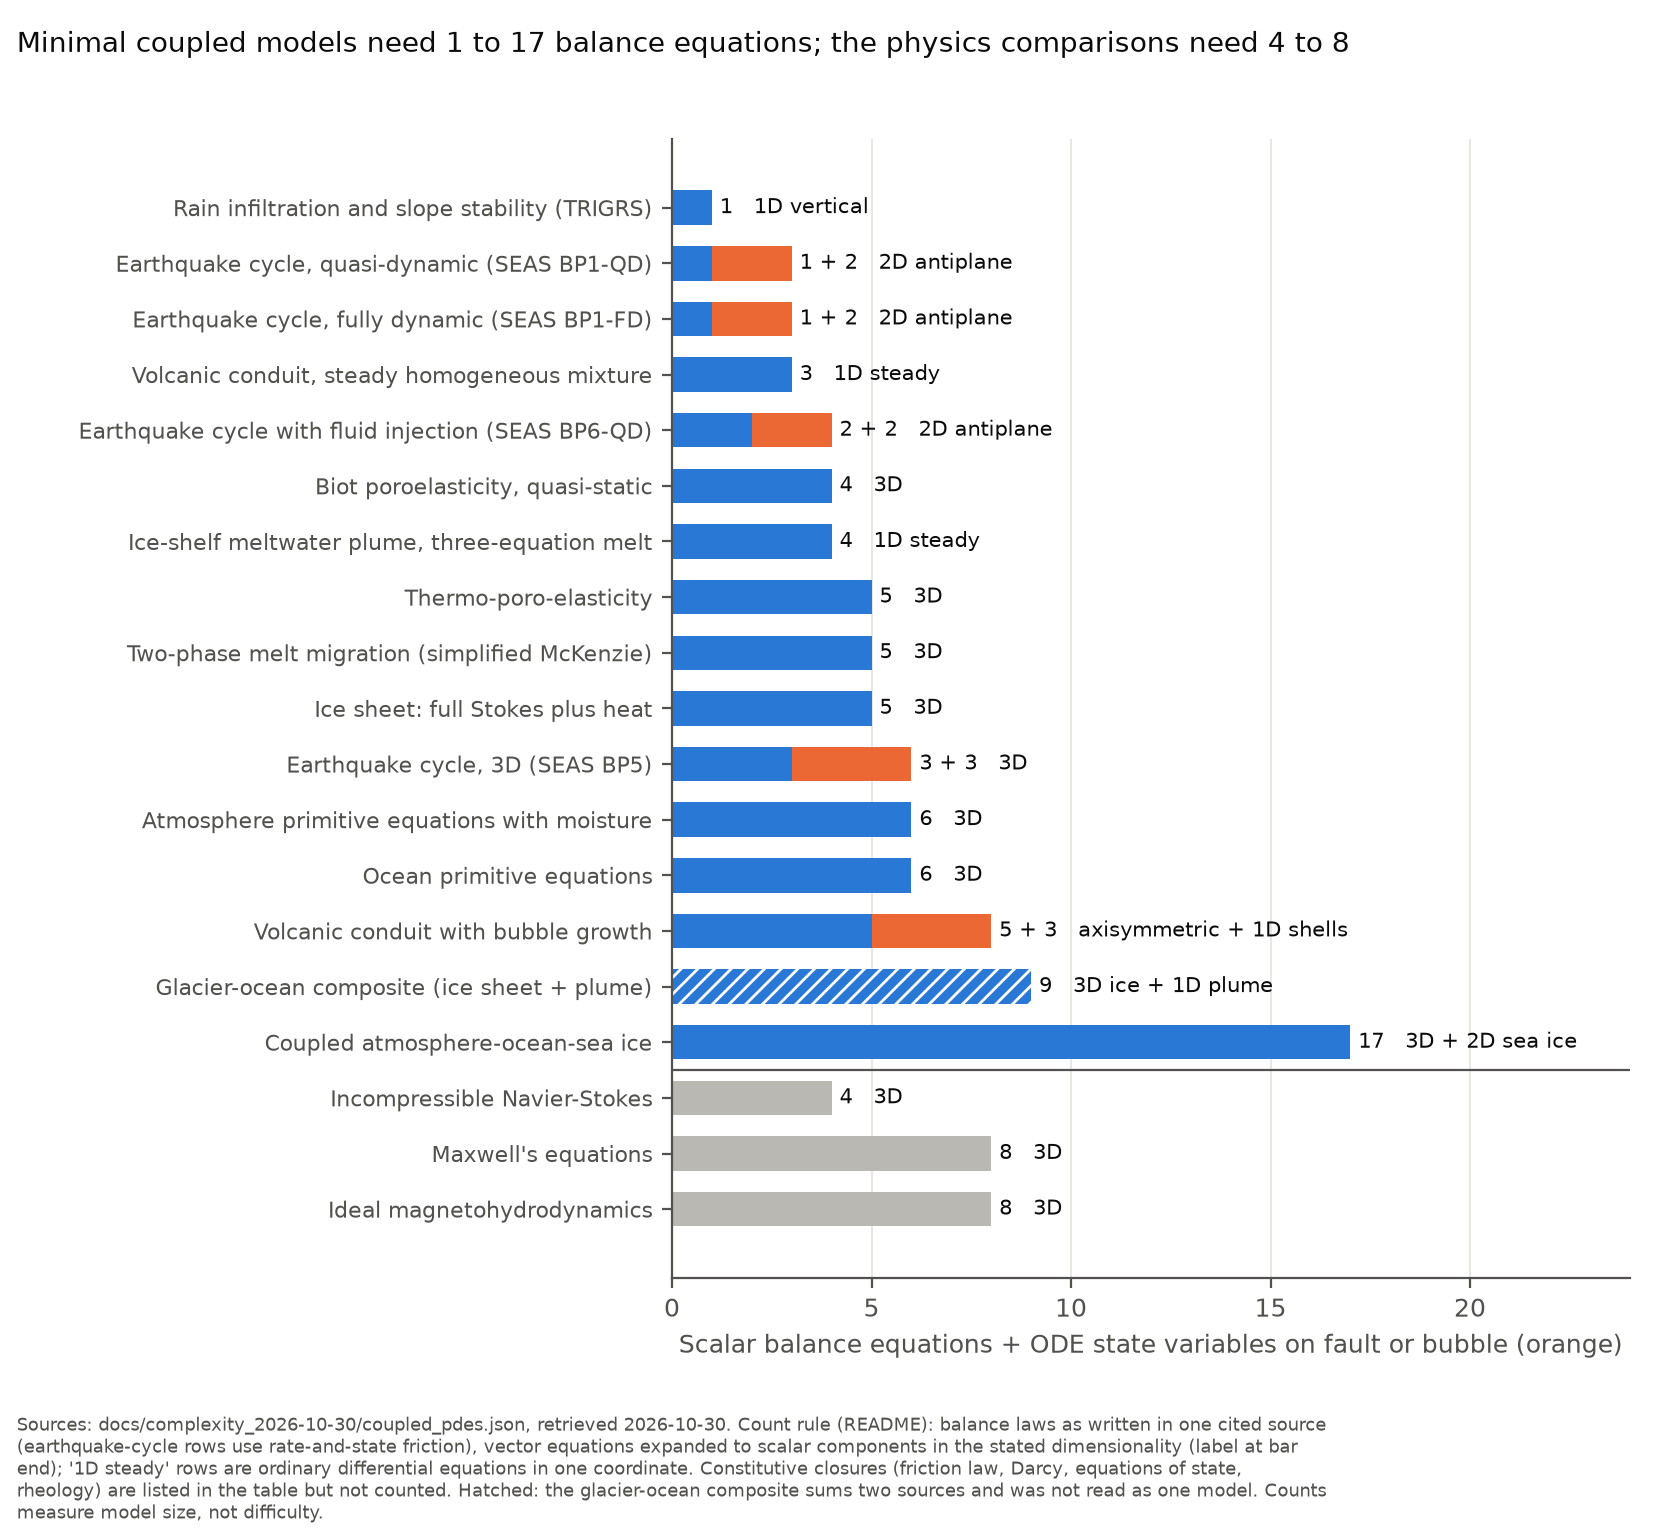

In [5]:
pdes = tables["coupled_pdes.json"]["rows"]
table(["id", "System", "Dimensions", "Scalar balance eqs", "ODE states", "How counted", "Closures not counted"],
      [[r["id"], r["item"], r["dims_tag"], r["balance_equations_scalar_3d"], r["ode_state_variables"], r["value_text"],
        "; ".join(r["constitutive_closures"])] for r in pdes])
display(Image(str(FIG / "fig2_coupled_pde_counts.png"), width=760))

**Reading.** The coupled models are small systems; only the coupled climate core is larger than the physics comparisons. The difficulty lies in the closures listed in the last column (friction, permeability, rheology, melt physics), which are empirical and poorly constrained at depth. Hybrid models that keep the balance laws and learn the closures target exactly that.

## 4. Unobserved drivers of outcomes

In [6]:
uo = tables["unobserved_drivers.json"]["rows"]
table(["id", "Category", "Item", "As stated", "Source", "Read in text"],
      [[r["id"], r["category"], r["item"], r["value_text"], r["source"], r["checked_in_text"]] for r in uo])

| id | Category | Item | As stated | Source | Read in text |
|---|---|---|---|---|---|
| uo-01 | loss attribution (hazard vs exposure vs vulnerability) | Drivers of the historical increase in weather-disaster losses | qualitative: loss increase caused primarily by increasing exposure and value of capital at risk | Bouwer (2011), Bulletin of the American Meteorological Society | True |
| uo-02 | loss attribution (hazard vs exposure vs vulnerability) | Global vulnerability trend 1980-2016 | dropped by 6.5 (mortality) and nearly 5 times (economic loss rate) | Formetta & Feyen (2019), Global Environmental Change | True |
| uo-03 | loss attribution (hazard vs exposure vs vulnerability) | Relative impact of hazard (demand) vs vulnerability (capacity) epistemic uncertainty on earthquake loss | qualitative: capacity (vulnerability) uncertainty larger than demand (ground motion) uncertainty for a single scenario | Crowley et al. (2005), Earthquake Engineering & Structural Dynamics | True |
| uo-04 | loss attribution (hazard vs exposure vs vulnerability) | Variance-based sensitivity of portfolio loss epistemic uncertainty | qualitative: ranking only; design level (an exposure attribute) first, then fragility functions, median ground motion, GMPE, structural type | Markhvida et al. (2020), Proc. 17th World Conference on Earthquake Engineering (paper C000796) | True |
| uo-05 | loss attribution (hazard vs exposure vs vulnerability) | Peer-reviewed percentage share of seismic loss variance attributable to exposure vs vulnerability vs hazard | not found | not found | False |
| uo-06 | unmapped or unknown faults | Earthquake deaths by tectonic setting, ~1890-2010 | at least 1,400,000 deaths (continental interiors) vs 800,000 (plate boundaries) | England & Jackson (2011), Nature Geoscience | True |
| uo-07 | unmapped or unknown faults | Greendale fault, 2010 Mw 7.1 Darfield earthquake | 29.5 ± 0.5-km-long surface rupture | Quigley et al. (2012), Geology 40(1) | True |
| uo-08 | unmapped or unknown faults | 2016 Mw 7.8 Kaikoura multifault rupture | at least 12 major faults; rupture along both mapped and unmapped faults | Hamling et al. (2017), Science | True |
| uo-09 | unmapped or unknown faults | Share of 2023 surface rupture on previously mapped faults | not found (abstract states >500 km of rupture 'primarily' on the named East Anatolian (~345 km) and Cardak (~175 km) faults) | Reitman et al. (2023), The Seismic Record | True |
| uo-10 | unmapped or unknown faults | UCERF3 off-fault deformation | between 32% and 37% (UCERF2-implied: 27%) | Field et al. (2014), Bulletin of the Seismological Society of America 104(3) | True |
| uo-11 | unmapped or unknown faults | UCERF3 on-fault vs off-fault seismicity | 53% (UCERF3 smoothing, Fault Model 3.1) to 59% (Fault Model 3.2) | Field et al. (2014), Bulletin of the Seismological Society of America 104(3) | True |
| uo-12 | unmapped or unknown faults | Slip-rate observations on UCERF2 faults | Only about 30% | Field et al. (2014), Bulletin of the Seismological Society of America 104(3) | True |
| uo-13 | unmapped or unknown faults | GEM Global Active Faults Database (GAF-DB) | ∼13,500 faults; about 77% with slip rate information | Styron & Pagani (2020), Earthquake Spectra | True |
| uo-14 | subsurface observation coverage | Seabed 2030 / GEBCO 2026 Grid | 28.7% | Nippon Foundation-GEBCO Seabed 2030 announcement, reported by Hellenic Shipping News | True |
| uo-15 | subsurface observation coverage | Kola superdeep well SG-3 | 12,262 m | Popov et al. (1999), Tectonophysics | False |
| uo-16 | subsurface observation coverage | In situ groundwater-level monitoring synthesized globally | 170,000 monitoring wells and 1,693 aquifer systems | Jasechko et al. (2024), Nature | True |
| uo-17 | subsurface observation coverage | Detailed (7.5-minute quadrangle, ~1:24,000) geologic map coverage | Only 19.6 percent | Soller & Berg (1997), Geotimes ('The National Geologic Map Database -- A Progress Report'), hosted by USGS NGMDB | True |
| uo-18 | subsurface observation coverage | Geologic map coverage at adequate detail (NCGMP fact sheet) | Less than 50 percent | American Geosciences Institute (2018), Geoscience Currents fact sheet 'Geologic Mapping for the Nation: The NCGMP' | True |
| uo-19 | exposure / building inventory gaps | OpenStreetMap building completeness | 1,848 urban centres (16% of the urban population) exceed 80%; 9,163 cities (48% of the urban population) below 20% | Herfort et al. (2023), Nature Communications | True |
| uo-20 | exposure / building inventory gaps | Urban population in slums or informal settlements (SDG 11.1.1) | an estimated 1.13 billion people | UN Statistics Division (2026), SDG Extended Report 2026, Goal 11 | True |
| uo-21 | exposure / building inventory gaps | Number of countries with a national building inventory (vs. exposure inferred from census/housing statistics) | not found | Yepes-Estrada et al. (2023), Earthquake Spectra (abstract only) and GEM exposure documentation | False |
| uo-22 | exposure / building inventory gaps | Population exposure uncertainty from choice of gridded population dataset | 134, 122, and 101 million (LandScan, WorldPop, HRSL); reduction up to ~60% in single countries | Smith et al. (2019), Nature Communications | True |
| uo-23 | loss and event reporting gaps | Missing loss fields in EM-DAT, 1990-2020 | missing for 96.2% (reconstruction costs), 88.1% (insured damages), 41.5% (total estimated damages); total deaths 1.3% | Jones, Guha-Sapir & Tubeuf (2022), Scientific Data | True |
| uo-24 | loss and event reporting gaps | Missing economic loss in EM-DAT, 2000-2020 | 11143 entries ... 80.38% of the total | CRED (2021), Cred Crunch No. 63 'Missing data on economic losses variables from EM-DAT' | True |
| uo-25 | loss and event reporting gaps | EM-DAT undercount of fatal landslides | underestimated the number of fatal landslide events by ∼ 2000 % and fatalities by 430 % | Froude & Petley (2018), Natural Hazards and Earth System Sciences (citing Petley 2012) | True |
| uo-26 | observation network coverage | Global stream gauge network placement | 32,091 stream gauges | Krabbenhoft et al. (2022), Nature Sustainability | True |
| uo-27 | observation network coverage | Decline of river gauging network / GRDC data availability | not found (qualitative only: 'possible decline in network coverage') | Hannah et al. (2011), Hydrological Processes | True |
| uo-28 | observation network coverage | Population with access to earthquake early warning | 260 million people (plus ~150 million Android early-warning users in the first year) | Allen & Stogaitis (2022), Science | True |
| uo-29 | observation network coverage | Share of population or seismic-hazard area within a given distance of a seismic or strong-motion station | not found | not found | False |

**Reading.** Outcome labels are thin (missing loss fields in EM-DAT), exposure is weakly observed (OpenStreetMap building completeness), and a large share of California deformation sits outside the modeled fault network. No peer-reviewed percentage splits seismic loss variance between hazard, exposure and vulnerability (row `uo-05`).

## 5. AI evidence along the four axes

Successes and limitations were both sought. The counts reflect what was collected, not how often AI succeeds.

In [7]:
ai = [r for r in tables["ai_evidence.json"]["rows"] if valued(r)]
table(["Axis", "Successes", "Limitations"],
      [[ax, sum(r["axis"] == ax and r["evidence_type"] == "success" for r in ai), sum(r["axis"] == ax and r["evidence_type"] == "limitation" for r in ai)]
       for ax in ("dimensionality", "closures", "tails", "unobserved")])
table(["id", "Axis", "Type", "Task", "As stated", "Baseline", "Source"],
      [[r["id"], r["axis"], r["evidence_type"], r["task"], r["value_text"], r["baseline"] or "", r["source"]] for r in ai])

| Axis | Successes | Limitations |
|---|---|---|
| dimensionality | 8 | 2 |
| closures | 5 | 3 |
| tails | 1 | 3 |
| unobserved | 3 | 3 |

| id | Axis | Type | Task | As stated | Baseline | Source |
|---|---|---|---|---|---|---|
| ai-01 | dimensionality | success | earthquake detection (template matching, not deep learning) | a catalog with 1.81 million earthquakes, a 10-fold increase | standard Southern California Seismic Network catalog | Ross et al. (2019), Science |
| ai-02 | dimensionality | success | earthquake detection and phase picking (EQTransformer) | two times more earthquakes using only a portion (less than 1/3) of seismic stations | existing catalog for the 2000 Tottori aftershock period (Japan) | Mousavi et al. (2020), Nature Communications |
| ai-03 | dimensionality | success | seismic P and S arrival picking (PhaseNet) | F1 0.896 for P and 0.801 for S, vs AR picker 0.558 (P) and 0.165 (S) | autoregressive (AR) picker | Zhu & Beroza (2019), Geophysical Journal International |
| ai-04 | dimensionality | success | global medium-range weather forecasting (GraphCast) | outperforms the most accurate operational deterministic systems on 90% of 1380 verification targets | ECMWF HRES (operational deterministic) | Lam et al. (2023), Science |
| ai-05 | dimensionality | success | global medium-range weather forecasting (Pangu-Weather) | RMSE of 5-day Z500 forecast of 296.7 vs 333.7 (operational IFS) and 462.5 (FourCastNet) | ECMWF operational IFS | Bi et al. (2023), Nature |
| ai-06 | dimensionality | success | global probabilistic weather forecasting (GenCast) | greater skill than ENS on 97.2% of 1,320 targets | ECMWF ENS (operational ensemble) | Price et al. (2025), Nature |
| ai-07 | dimensionality | success | earthquake detection on distributed acoustic sensing (PhaseNet-DAS) | PhaseNet-DAS v1 detects 2-5 times more events than PhaseNet across four DAS cables | PhaseNet (station-trained) applied channel by channel | Zhu et al. (2023), Nature Communications |
| ai-08 | dimensionality | success | InSAR time-series deformation detection (deep autoencoder) | reaches 2 mm detection, revealing a slow earthquake twice as extensive as previously recognized | conventional InSAR analysis with expert interpretation and prior fault knowledge | Rouet-Leduc et al. (2021), Nature Communications |
| ai-09 | dimensionality | limitation | global medium-range weather forecasting (Pangu-Weather spectra) | effective resolution of Pangu-Weather forecasts is closer to 500-700 km than to the nominal 0.25 deg | ERA5 analysis spectra; ECMWF IFS forecasts | Bonavita (2024), Geophysical Research Letters |
| ai-10 | dimensionality | limitation | error growth from small initial perturbations (Pangu-Weather) | underestimation of the DKE by five orders of magnitude compared to ICON | ICON physics-based model incl. convection-permitting run | Selz & Craig (2023), Geophysical Research Letters |
| ai-11 | closures | success | neural-network subgrid convection and cloud parameterization (NNCAM) | physical parameterization of NNCAM is 20 times faster than SPCAM and 8 times faster than CTRLCAM; total model speed-up factor 10 | superparameterized CAM (SPCAM, embedded cloud-resolving model) | Rasp, Pritchard & Gentine (2018), PNAS |
| ai-12 | closures | limitation | neural-network subgrid parameterization under warming (NNCAM) | NNCAM trained on reference climate only is unable to generalize to much warmer climates (+4K SST) | SPCAM +4K SST simulation | Rasp, Pritchard & Gentine (2018), PNAS |
| ai-13 | closures | success | hybrid differentiable dynamical core with learned physics (NeuralGCM) climate run | ensemble mean temperature RMSE for NeuralGCM stands at 0.16K ... climatology's RMSE of 0.45K | climatology; ERA5 | Kochkov et al. (2024), Nature |
| ai-14 | closures | limitation | hybrid GCM (NeuralGCM) under imposed SST warming | for more substantial SST increases (+4K), NeuralGCM's response diverges from expectations | expected warming response (physics-based GCMs) | Kochkov et al. (2024), Nature |
| ai-15 | closures | success | laboratory earthquake time-to-failure from acoustic emission (random forest) | R2 value of 0.89 (naive periodicity model: 0.3) | naive model using only event periodicity | Rouet-Leduc et al. (2017), Geophysical Research Letters |
| ai-17 | tails | limitation | forecasting record-breaking heat, cold and wind (deterministic AI models) | HRES still consistently outperforms state-of-the-art AI models ...; 162,751 heat, 32,991 cold, and 53,345 wind records | ECMWF HRES | Zhang et al. (2026), Science Advances |
| ai-18 | tails | success | probabilistic forecasting of record-breaking heat extremes (WeatherNext2, WeatherGen) | WeatherNext2 achieves Brier skill scores over the IFS of 23% at the 90th percentile and 24% (23-26%) for record-breaking extreme events | ECMWF IFS ensemble (raw); EMOS post-processed IFS | Wessel et al. (2026), arXiv preprint 2610.20519 |
| ai-19 | tails | limitation | forecasting out-of-distribution Category 5 tropical cyclones (FourCastNet) | mslp barely reaches below 980 hPa | FourCastNet trained on full ERA5 1979-2015; ERA5 truth | Sun et al. (2025), PNAS |
| ai-20 | tails | limitation | real-time earthquake magnitude estimation for early warning (TEAM-LM transformer) | saturation starts ... around 5.5 for Italy and 6.0 for Chile | catalog magnitude (MA Chile, ML Italy, MJMA Japan) | Munchmeyer et al. (2021), Geophysical Journal International |
| ai-22 | closures | limitation | spatial aftershock forecasting (logistic regression vs deep learning) | AUC = 0.85 using 2 free parameters versus the 13,451 parameters ...; improved AUC = 0.86 | DeVries et al. (2018) deep neural network (AUC 0.85, 13,451 parameters) | Mignan & Broccardo (2019), Nature |
| ai-23 | unobserved | success | building footprint extraction from 50 cm satellite imagery (Open Buildings, Africa) | 516M Africa-wide detected footprints |  | Sirko et al. (2021), arXiv preprint 2107.12283 |
| ai-24 | unobserved | limitation | building footprint extraction (Open Buildings, Africa) imagery coverage | 19.4M km2, 64% of the land surface of the continent |  | Sirko et al. (2021), arXiv preprint 2107.12283 |
| ai-25 | unobserved | success | global building footprint extraction (Microsoft / Bing Maps) | We have detected 1.4B buildings from Bing Maps imagery between 2014 and 2024 |  | Microsoft (2026), GlobalMLBuildingFootprints repository README |
| ai-26 | unobserved | limitation | global building footprint extraction (Microsoft), regional recall | Africa precision 94.4%, recall 70.9% (Europe 94.3% / 85.9%) | region-specific labelled evaluation sets | Microsoft (2026), GlobalMLBuildingFootprints repository README |
| ai-27 | unobserved | success | deep-learning-picked catalog revealing activated fault structures (central Italy 2016-2017) | catalog of ~900,000 earthquakes ... an order of magnitude more events than the catalog routinely produced | routine catalog of the local monitoring agency (INGV) | Tan et al. (2021), The Seismic Record |
| ai-28 | unobserved | limitation | cross-domain transfer of deep-learning seismic detectors (regional to teleseismic) | no model trained on a regional dataset reaches an AUC score above 0.75 for detection on GEOFON ... in-domain performance of 0.85 to 0.99 | in-domain performance of the same models (AUC 0.85-0.99) | Munchmeyer et al. (2022), JGR Solid Earth |
| ai-30 | closures | success | earthquake forecasting with a neural temporal point process (RECAST) | improved fit and forecast accuracy compared to our benchmark when the training set is sufficiently long (>10^4 events) | temporal ETAS model | Dascher-Cousineau et al. (2023), Geophysical Research Letters |
| ai-31 | closures | success | short-term earthquake forecasting with a neural point process | both models perform similarly above M3; lowering the threshold to M1.2 reduces the performance of ETAS unlike the neural model | temporal ETAS model | Stockman, Lawson & Werner (2023), Earth's Future |

## 6. Readiness profile by discipline

Each column is a separate measure; a cell has a status (measured, partial, not found, not assessed) and cites the rows it rests on. Nothing is summed.

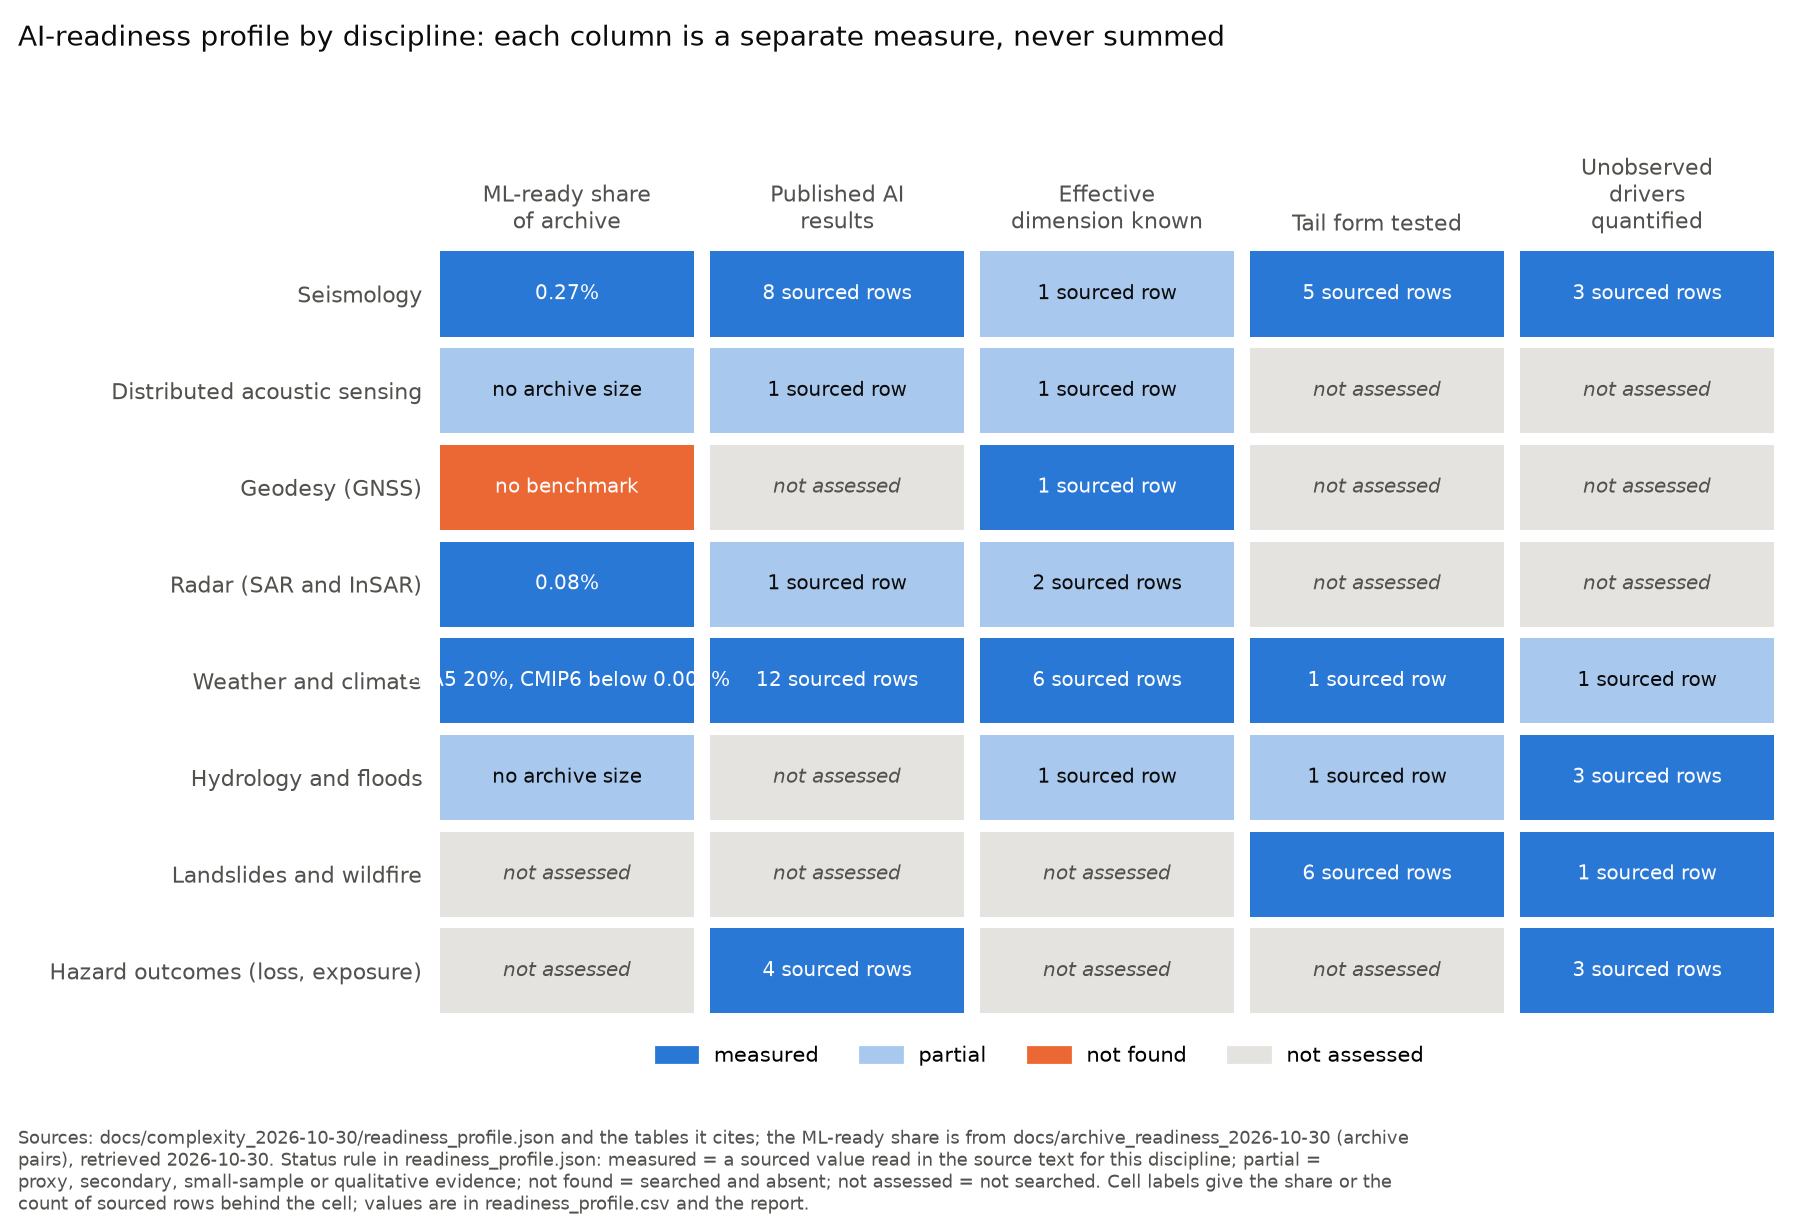

| Discipline | Measure | Status | Label | Evidence |
|---|---|---|---|---|
| Seismology | ML-ready share of archive | measured | 0.27% | pair:Seismology |
| Seismology | Published AI results | measured | 8 sourced rows | ai-02; ai-03; ai-27; ai-20; ai-28; ai-22; ai-30; ai-31 |
| Seismology | Effective dimension known | partial | 1 sourced row | dim-17; dim-18 |
| Seismology | Tail form tested | measured | 5 sourced rows | pl-02; pl-03; pl-04; pl-05; pl-08 |
| Seismology | Unobserved drivers quantified | measured | 3 sourced rows | uo-10; uo-12; uo-06 |
| Distributed acoustic sensing | ML-ready share of archive | partial | no archive size | pair:DAS |
| Distributed acoustic sensing | Published AI results | partial | 1 sourced row | ai-07 |
| Distributed acoustic sensing | Effective dimension known | partial | 1 sourced row | dim-13 |
| Distributed acoustic sensing | Tail form tested | not assessed |  |  |
| Distributed acoustic sensing | Unobserved drivers quantified | not assessed |  |  |
| Geodesy (GNSS) | ML-ready share of archive | not found | no benchmark | pair:Geodesy: GNSS |
| Geodesy (GNSS) | Published AI results | not assessed |  |  |
| Geodesy (GNSS) | Effective dimension known | measured | 1 sourced row | dim-24; dim-25 |
| Geodesy (GNSS) | Tail form tested | not assessed |  |  |
| Geodesy (GNSS) | Unobserved drivers quantified | not assessed |  |  |
| Radar (SAR and InSAR) | ML-ready share of archive | measured | 0.08% | pair:SAR: Sentinel-1 |
| Radar (SAR and InSAR) | Published AI results | partial | 1 sourced row | ai-08 |
| Radar (SAR and InSAR) | Effective dimension known | partial | 2 sourced rows | dim-21; dim-22 |
| Radar (SAR and InSAR) | Tail form tested | not assessed |  |  |
| Radar (SAR and InSAR) | Unobserved drivers quantified | not assessed |  |  |
| Weather and climate | ML-ready share of archive | measured | ERA5 20%, CMIP6 below 0.001% | pair:Reanalysis: ERA5; pair:Climate projections: CMIP6 |
| Weather and climate | Published AI results | measured | 12 sourced rows | ai-04; ai-05; ai-06; ai-09; ai-10; ai-11; ai-12; ai-13; ai-14; ai-17; ai-18; ai-19 |
| Weather and climate | Effective dimension known | measured | 6 sourced rows | dim-26; dim-27; dim-28; dim-31; dim-32; dim-33; dim-05 |
| Weather and climate | Tail form tested | measured | 1 sourced row | pl-26 |
| Weather and climate | Unobserved drivers quantified | partial | 1 sourced row | uo-01; uo-02 |
| Hydrology and floods | ML-ready share of archive | partial | no archive size | pair:Hydrology: gauges |
| Hydrology and floods | Published AI results | not assessed |  |  |
| Hydrology and floods | Effective dimension known | partial | 1 sourced row | dim-29 |
| Hydrology and floods | Tail form tested | partial | 1 sourced row | pl-14 |
| Hydrology and floods | Unobserved drivers quantified | measured | 3 sourced rows | uo-26; uo-16; uo-27; uo-22 |
| Landslides and wildfire | ML-ready share of archive | not assessed |  |  |
| Landslides and wildfire | Published AI results | not assessed |  |  |
| Landslides and wildfire | Effective dimension known | not assessed |  |  |
| Landslides and wildfire | Tail form tested | measured | 6 sourced rows | pl-10; pl-11; pl-12; pl-22; pl-23; pl-24 |
| Landslides and wildfire | Unobserved drivers quantified | measured | 1 sourced row | uo-25 |
| Hazard outcomes (loss, exposure) | ML-ready share of archive | not assessed |  |  |
| Hazard outcomes (loss, exposure) | Published AI results | measured | 4 sourced rows | ai-23; ai-24; ai-25; ai-26 |
| Hazard outcomes (loss, exposure) | Effective dimension known | not assessed |  |  |
| Hazard outcomes (loss, exposure) | Tail form tested | not assessed |  |  |
| Hazard outcomes (loss, exposure) | Unobserved drivers quantified | measured | 3 sourced rows | uo-23; uo-24; uo-19; uo-05; uo-03; uo-04 |

In [8]:
display(Image(str(FIG / "fig3_readiness_profile.png"), width=820))
with open(FIG / "readiness_profile.csv") as fh:
    cells = list(csv.DictReader(fh))
table(["Discipline", "Measure", "Status", "Label", "Evidence"], [[c["discipline"], c["column"], c["status"], c["label"], c["evidence"]] for c in cells])

## What this notebook does not claim

- That geoscience is more complex than other fields: where comparisons exist, the geoscience values overlap them.
- A single readiness or complexity score.
- How common AI success is: the evidence table is a purposive sample with both successes and limitations.
- Anything about cells marked not assessed: they were not searched.